# EN3150 Assignment 03: Model A (Standard CNN), shared pipeline

This notebook retrains **Model A** using exactly the same pipeline as `Model_B/src/ModelB.ipynb`, so the
Model A vs Model B comparison isolates the effect of replacing standard convolutions with depthwise
separable convolutions.

| Held identical to Model B | Value |
|---|---|
| Data | `splits/*.csv` (70/15/15, 18,648 / 3,996 / 3,996), 64x64 input |
| Preprocessing and augmentation | `Common/dataset.py` (colour jitter, rotation, small affine, normalise to [-1, 1]) |
| Training loop | `Common/training.py` `train_model` (best-validation-loss weights restored) |
| Optimizer | Read from `results/Optimizer/selected_optimizer.txt` (Adam, lr = 1e-3) |
| Epochs / batch size / loss | 25 / 32 / cross-entropy |
| Evaluation | `Common/evaluation.py` (same metrics, plots, size and timing functions) |

It replaces the group's earlier Model A notebook (own data pipeline, 20 epochs), which remains available in the git history.

In [1]:
import json
import random
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.metrics import confusion_matrix, classification_report

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce GTX 1660 Ti


In [4]:
def find_project_root():
    current = Path.cwd().resolve()

    while current != current.parent:
        if (current / ".git").exists():
            return current

        current = current.parent

    raise FileNotFoundError("Could not find project root.")


PROJECT_ROOT = find_project_root()

DATA_ROOT = PROJECT_ROOT / "data" / "gtsrb"
SPLIT_DIR = PROJECT_ROOT / "splits"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "Model_A"
METRICS_DIR = RESULTS_DIR / "Model_A"

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: E:\UOM resourses\Sem 5\Pattern Recognition\Assignment 3


In [5]:
from Common.dataset import create_dataloaders
from Common.models import ModelA, count_parameters
from Common.training import train_model, create_optimizer
from Common.evaluation import (
    get_predictions,
    calculate_metrics,
    plot_training_curves,
    plot_confusion_matrix,
    print_classification_report,
    total_parameters,
    estimated_fp32_size_kb,
    save_model_and_get_size,
    measure_inference_time
)

## 1. Data preparation

The shared split files are loaded and wrapped in data loaders by `Common/dataset.py`. Images are resized to
$64 \times 64$; only the training set is augmented.

In [6]:
train_df = pd.read_csv(SPLIT_DIR / "train_split.csv")
val_df = pd.read_csv(SPLIT_DIR / "val_split.csv")
test_df = pd.read_csv(SPLIT_DIR / "test_split.csv")

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 18648
Validation: 3996
Test: 3996


In [7]:
train_loader, val_loader, test_loader = create_dataloaders(
    train_df=train_df,
    val_df=val_df,
    test_df=test_df,
    data_root=DATA_ROOT,
    batch_size=32,
    num_workers=0
)

### 1.1 Split checks

Confirm the 70/15/15 proportions, that no image appears in more than one split, and that all 43 classes are
present in every split.

In [8]:
total = len(train_df) + len(val_df) + len(test_df)
print(
    f"Split proportions: train={len(train_df) / total:.1%}, "
    f"validation={len(val_df) / total:.1%}, test={len(test_df) / total:.1%}"
)

train_paths, val_paths, test_paths = set(train_df.Path), set(val_df.Path), set(test_df.Path)
assert not train_paths & val_paths
assert not train_paths & test_paths
assert not val_paths & test_paths
print("Splits are disjoint.")

class_table = pd.DataFrame({
    "Train": train_df.ClassId.value_counts(),
    "Validation": val_df.ClassId.value_counts(),
    "Test": test_df.ClassId.value_counts()
}).sort_index()
print("Classes represented (train/validation/test):", *class_table.notna().sum().tolist())
class_table

Split proportions: train=70.0%, validation=15.0%, test=15.0%
Splits are disjoint.
Classes represented (train/validation/test): 43 43 43


,Train,Validation,Test
ClassId,,,
0,117,14,19
1,1051,226,223
2,1029,238,233
3,674,138,148
4,910,189,221
5,866,185,209
6,221,32,47
7,669,136,155
8,678,138,144


### 1.2 Batch checks and sample images

Image batch shape: (32, 3, 64, 64)
Image values: min=-1.000, max=1.000
Batch checks passed.


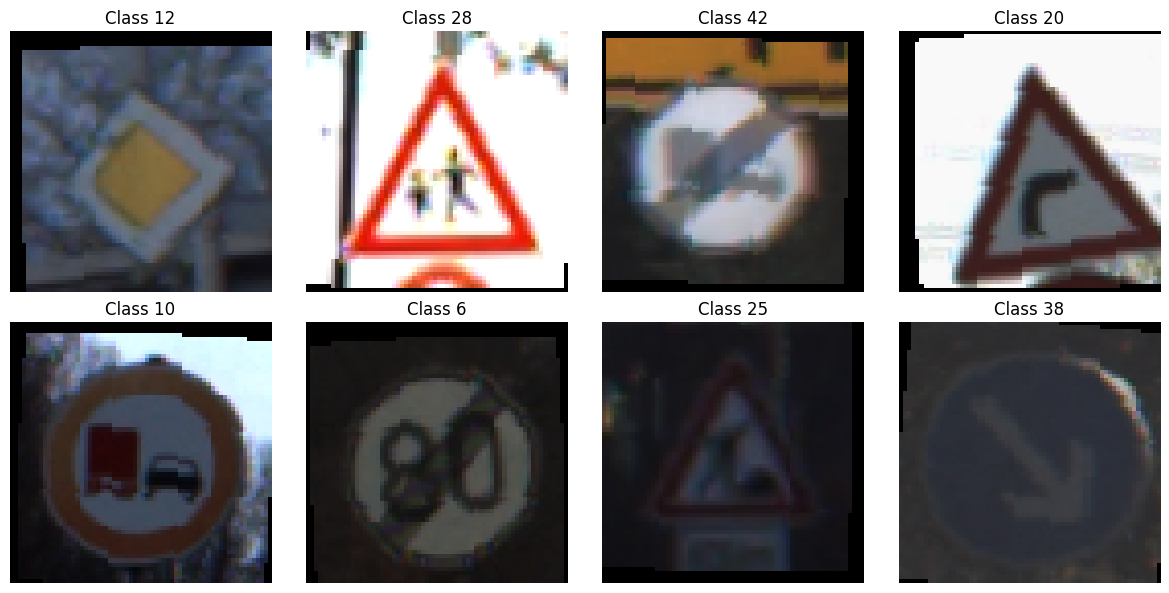

In [9]:
images, labels = next(iter(train_loader))

print(f"Image batch shape: {tuple(images.shape)}")
print(f"Image values: min={images.min().item():.3f}, max={images.max().item():.3f}")
assert images.shape[1:] == (3, 64, 64)
assert torch.isfinite(images).all()
assert labels.min() >= 0 and labels.max() < 43
print("Batch checks passed.")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow((image.permute(1, 2, 0) * 0.5 + 0.5).clamp(0, 1))
    ax.set_title(f"Class {label.item()}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 1.3 Untimed warm-up

Every image file is read once before training so the operating system caches it. Without this, the first timed
epoch would also include reading the dataset from disk, which made it 2-3x slower than the others in an earlier run.

In [10]:
start = time.perf_counter()
for split_df in (train_df, val_df, test_df):
    for relative_path in split_df.Path:
        (DATA_ROOT / relative_path).read_bytes()
print(f"Warm-up: read {len(train_df) + len(val_df) + len(test_df):,} image files in {time.perf_counter() - start:.1f} s")

Warm-up: read 26,640 image files in 42.5 s


## 2. Model A architecture

Four blocks of `Conv2d(3x3, stride 1, padding 1) -> ReLU -> MaxPool2d(2x2)`, then `Flatten -> Linear(512, 43)`.

| Layer | Output shape | Parameters |
|---|---|---|
| Conv 3 -> 16 | 16 x 64 x 64 (pool -> 32 x 32) | 3·3·3·16 + 16 = 448 |
| Conv 16 -> 32 | 32 x 32 x 32 (pool -> 16 x 16) | 3·3·16·32 + 32 = 4,640 |
| Conv 32 -> 32 | 32 x 16 x 16 (pool -> 8 x 8) | 3·3·32·32 + 32 = 9,248 |
| Conv 32 -> 32 | 32 x 8 x 8 (pool -> 4 x 4) | 9,248 |
| Linear 512 -> 43 | 43 | 512·43 + 43 = 22,059 |
| **Total** | | **45,643** |

ReLU is used throughout: it is a single comparison per value (`max(0, x)`), avoiding the exponentials needed
by sigmoid or tanh, which is cheaper on microcontrollers and suits integer quantisation.

In [11]:
model_a = ModelA().to(device)
print(model_a)

parameters_a = count_parameters(model_a)
print("Model A trainable parameters:", parameters_a)
assert parameters_a == 45643

for name, parameter in model_a.named_parameters():
    print(f"{name:22s} {str(tuple(parameter.shape)):18s} {parameter.numel():>7,}")

ModelA(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=512, out_features=43, bias=True)
  )
)
Model A trainable parameters: 45643
features.0.weight      (16, 3, 3, 3)          432
features.0.bias        (16,)          

### 2.1 Forward-pass smoke check

In [12]:
model_a.eval()
with torch.inference_mode():
    logits = model_a(images.to(device))
assert logits.shape == (images.shape[0], 43)
assert torch.isfinite(logits).all()
print(f"Smoke check passed: {tuple(images.shape)} -> {tuple(logits.shape)}")

Smoke check passed: (32, 3, 64, 64) -> (32, 43)


## 3. Training

Same optimizer, epochs and seed as Model B. The model and optimizer are recreated after re-seeding so the
run is reproducible.

In [13]:
selected_optimizer = (RESULTS_DIR / "Optimizer" / "selected_optimizer.txt").read_text().strip()
print("Final optimizer:", selected_optimizer)

Final optimizer: Adam


In [14]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)


model_a = ModelA().to(device)

criterion = nn.CrossEntropyLoss()

optimizer_a = create_optimizer(selected_optimizer, model_a.parameters())

In [15]:
model_a, history_a = train_model(
    model=model_a,
    train_loader=train_loader,
    val_loader=val_loader,
    optimizer=optimizer_a,
    criterion=criterion,
    epochs=25,
    device=device
)

METRICS_DIR.mkdir(parents=True, exist_ok=True)
with (METRICS_DIR / "model_a_history.json").open("w", encoding="utf-8") as history_file:
    json.dump(history_a, history_file, indent=2)

Epoch 01/25 | Train Loss: 2.3765 | Train Acc: 0.3103 | Val Loss: 1.3426 | Val Acc: 0.5781 | Time: 39.34s


Epoch 02/25 | Train Loss: 1.1328 | Train Acc: 0.6335 | Val Loss: 0.6187 | Val Acc: 0.7920 | Time: 41.08s


Epoch 03/25 | Train Loss: 0.6154 | Train Acc: 0.7985 | Val Loss: 0.3779 | Val Acc: 0.8734 | Time: 38.93s


Epoch 04/25 | Train Loss: 0.3947 | Train Acc: 0.8736 | Val Loss: 0.1945 | Val Acc: 0.9384 | Time: 39.73s


Epoch 05/25 | Train Loss: 0.2833 | Train Acc: 0.9114 | Val Loss: 0.1670 | Val Acc: 0.9474 | Time: 39.77s


...

Epoch 21/25 | Train Loss: 0.0549 | Train Acc: 0.9835 | Val Loss: 0.0295 | Val Acc: 0.9912 | Time: 41.67s


Epoch 22/25 | Train Loss: 0.0674 | Train Acc: 0.9792 | Val Loss: 0.0453 | Val Acc: 0.9855 | Time: 41.64s


Epoch 23/25 | Train Loss: 0.0579 | Train Acc: 0.9817 | Val Loss: 0.0348 | Val Acc: 0.9892 | Time: 42.37s


Epoch 24/25 | Train Loss: 0.0542 | Train Acc: 0.9836 | Val Loss: 0.0402 | Val Acc: 0.9885 | Time: 41.87s


Epoch 25/25 | Train Loss: 0.0493 | Train Acc: 0.9850 | Val Loss: 0.0309 | Val Acc: 0.9907 | Time: 41.80s


## 4. Evaluation

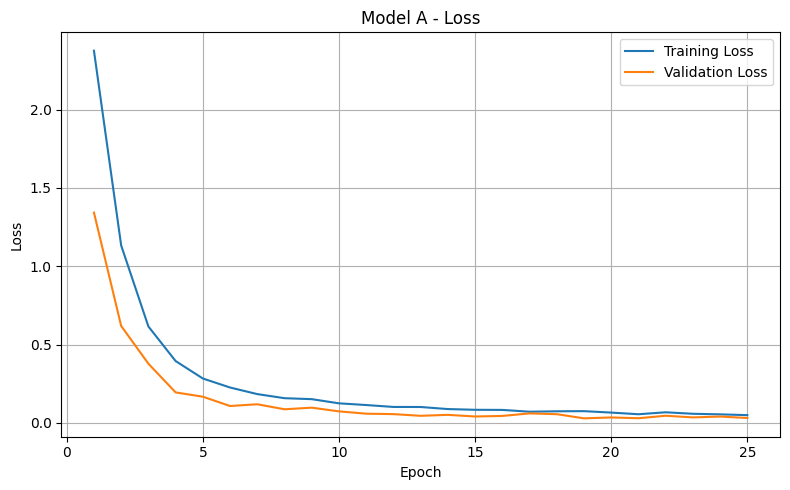

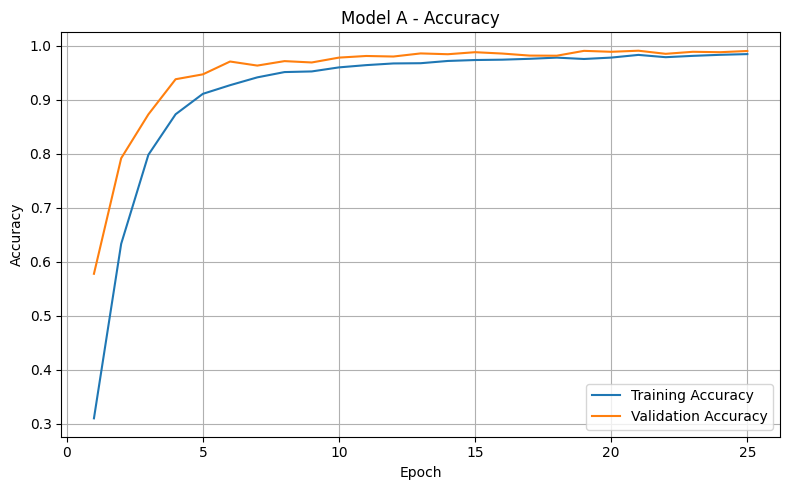

In [16]:
plot_training_curves(
    history=history_a,
    model_name="Model A",
    save_dir=FIGURES_DIR
)

In [17]:
y_true_a, y_pred_a = get_predictions(model_a, test_loader, device)

metrics_a = calculate_metrics(y_true_a, y_pred_a)

print(metrics_a)

{'Test Accuracy': 0.9897397397397397, 'Macro Precision': 0.9873789958750593, 'Macro Recall': 0.9916522373792314}


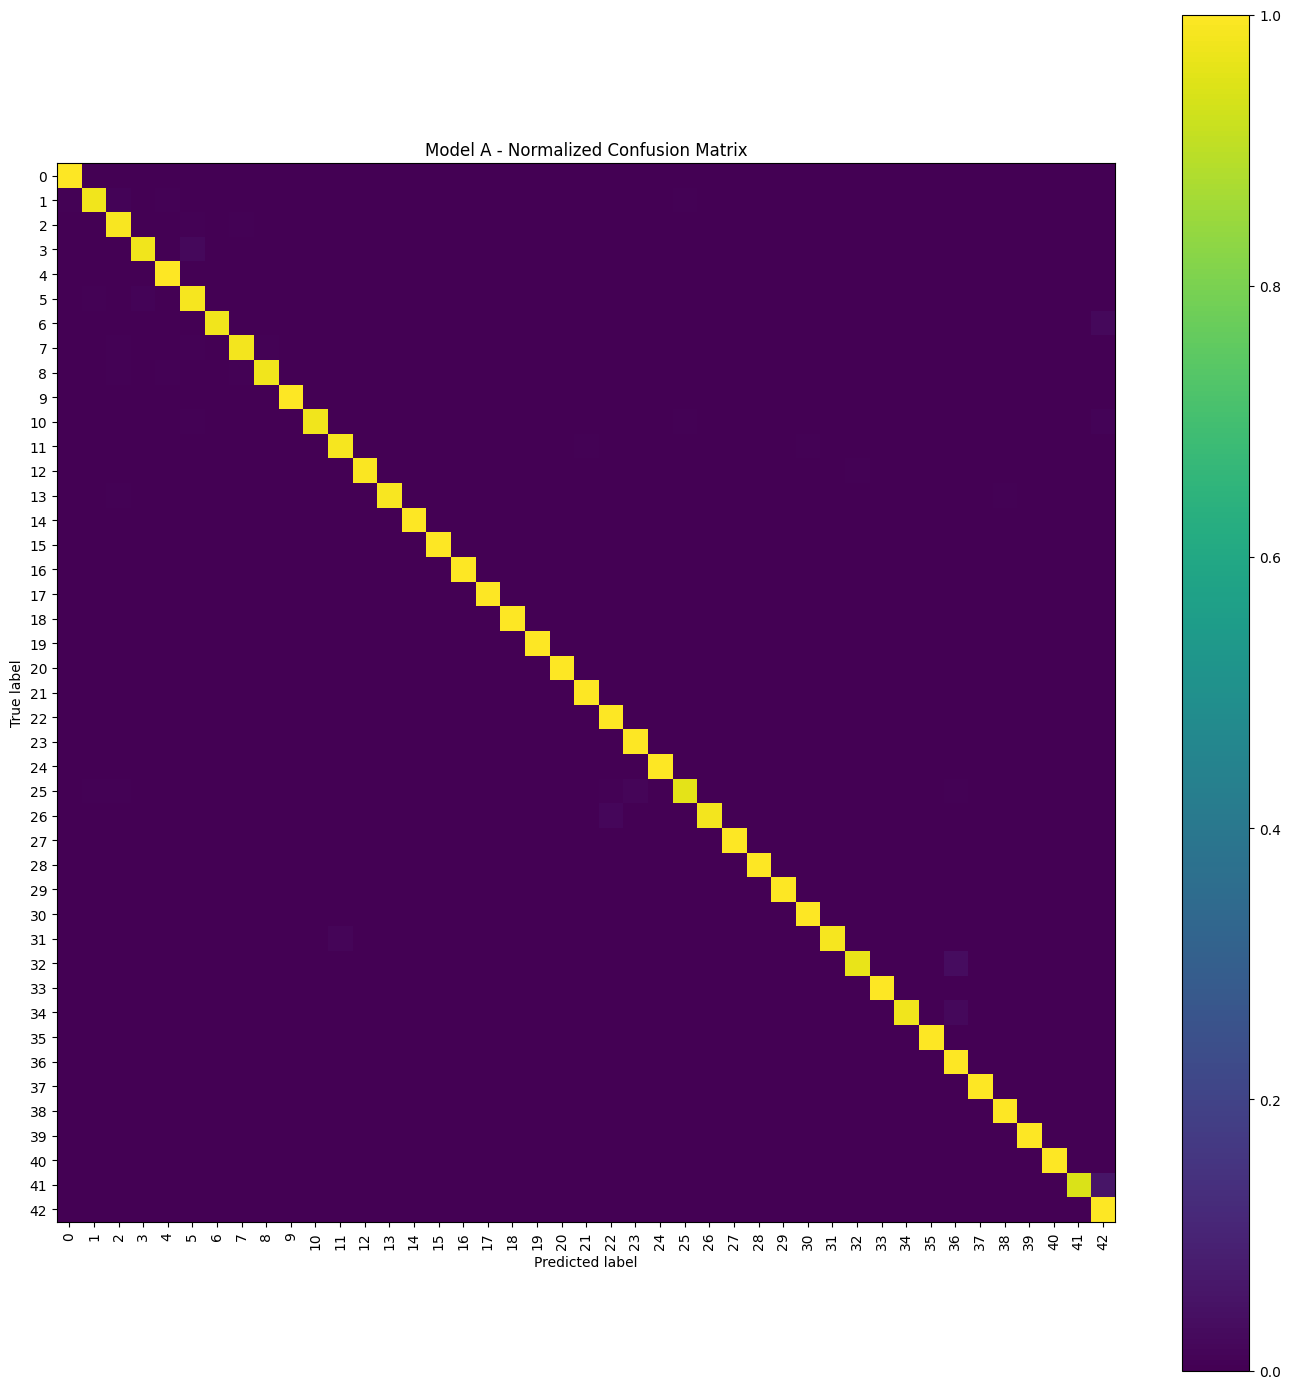

In [18]:
plot_confusion_matrix(
    y_true_a,
    y_pred_a,
    model_name="Model A",
    save_dir=FIGURES_DIR
)

In [19]:
report_a = classification_report(y_true_a, y_pred_a, output_dict=True, zero_division=0)
print_classification_report(y_true_a, y_pred_a)

with (METRICS_DIR / "model_a_classification_report.json").open("w", encoding="utf-8") as report_file:
    json.dump(report_a, report_file, indent=2)
np.savetxt(
    METRICS_DIR / "model_a_confusion_matrix.csv",
    confusion_matrix(y_true_a, y_pred_a, labels=list(range(43))),
    fmt="%d",
    delimiter=","
)

              precision    recall  f1-score   support

           0     0.9500    1.0000    0.9744        19
           1     0.9909    0.9776    0.9842       223
           2     0.9747    0.9914    0.9830       233
           3     0.9864    0.9797    0.9831       148
           4     0.9910    1.0000    0.9955       221
           5     0.9717    0.9856    0.9786       209
           6     1.0000    0.9787    0.9892        47
           7     0.9870    0.9806    0.9838       155
           8     0.9930    0.9792    0.9860       144
           9     1.0000    1.0000    1.0000       155
          10     1.0000    0.9797    0.9897       197
          11     0.9928    0.9856    0.9892       139
          12     1.0000    0.9953    0.9976       213
          13     1.0000    0.9906    0.9953       213
          14     1.0000    1.0000    1.0000        78
          15     1.0000    1.0000    1.0000        82
          16     1.0000    1.0000    1.0000        34
          17     1.0000    

## 5. Edge-deployment measurements

In [20]:
average_epoch_time_a = np.mean(history_a["epoch_time"])
median_epoch_time_a = np.median(history_a["epoch_time"])

print("Average epoch time:", average_epoch_time_a)
print("Median epoch time:", median_epoch_time_a)

Average epoch time: 40.86685420800059
Median epoch time: 40.984587300001294


In [21]:
parameters_a = total_parameters(model_a)

estimated_size_a = estimated_fp32_size_kb(model_a)

model_a_path = PROJECT_ROOT / "checkpoints" / "model_a_final.pth"

actual_size_a = save_model_and_get_size(model_a, model_a_path)

print("Parameters:", parameters_a)
print("Estimated size:", estimated_size_a, "KB")
print("Actual size:", actual_size_a, "KB")

Parameters: 45643
Estimated size: 178.29296875 KB
Actual size: 182.8486328125 KB


In [22]:
inference_time_a = measure_inference_time(model_a, test_loader, device)

print("Inference time:", inference_time_a, "ms/image")

Inference time: 0.3576378125217161 ms/image


In [23]:
model_a_results = {
    "Model": "Model A",
    "Parameters": parameters_a,
    "Estimated FP32 Size (KB)": estimated_size_a,
    "Actual Model Size (KB)": actual_size_a,
    "Average Epoch Time (s)": average_epoch_time_a,
    "Median Epoch Time (s)": median_epoch_time_a,
    "Inference Time (ms/image)": inference_time_a,
    "Test Accuracy": metrics_a["Test Accuracy"],
    "Macro Precision": metrics_a["Macro Precision"],
    "Macro Recall": metrics_a["Macro Recall"]
}

model_a_df = pd.DataFrame([model_a_results])

model_a_df.to_csv(METRICS_DIR / "model_a_metrics.csv", index=False)

model_a_df

,Model,Parameters,Estimated FP32 Size (KB),Actual Model Size (KB),Average Epoch Time (s),Median Epoch Time (s),Inference Time (ms/image),Test Accuracy,Macro Precision,Macro Recall
0,Model A,45643,178.292969,182.848633,40.866854,40.984587,0.357638,0.98974,0.987379,0.991652
